# GRU: next-word autoregressive generation

## imports

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/fgai-matplotlib')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import hashlib
import json
import math
import platform
import re
import time
from pathlib import Path
from statistics import mean
import numpy as np
import tensorflow as tf
from IPython.display import display, JSON, Markdown

GPUS = tf.config.list_physical_devices('GPU')
if not GPUS:
    raise RuntimeError('CUDA GPU unavailable. See the README library-path launch command, then restart the kernel.')
for gpu in GPUS:
    tf.config.experimental.set_memory_growth(gpu, True)
tf.keras.utils.set_random_seed(42)
print('TensorFlow:', tf.__version__)
print('GPU:', [tf.config.experimental.get_device_details(gpu) for gpu in GPUS])

DATASET_PATH = Path('dataset.npz')
with np.load(DATASET_PATH, allow_pickle=False) as data:
    arrays = {split: (data[split+'_x'].copy(), data[split+'_y'].copy())
              for split in ['train', 'val', 'test']}
    vocab = data['vocabulary'].tolist()
    metadata = json.loads(str(data['metadata_json'].item()))
CONTEXT = metadata['context']
BATCH_SIZE = 128
EPOCHS = 8
SEEDS = ['alice was beginning to get very tired', 'the white rabbit', 'she looked at the']
TEMPERATURES = [0.2, 0.5, 1.0]
print(json.dumps(metadata, indent=2))
for split, (x, y) in arrays.items():
    assert x.shape == (len(y), CONTEXT)
    assert not np.any(x == 0) and not np.any(y == 0)
    print(split, x.shape, y.shape)


I0000 00:00:1792262070.229316   21672 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792262072.340481   21672 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU: [{'compute_capability': (8, 6), 'device_name': 'NVIDIA GeForce RTX 3050 4GB Laptop GPU'}]
{
  "source": "https://www.gutenberg.org/cache/epub/11/pg11.txt",
  "raw_sha256": "01b38ea4c710a84bc18d0bd41271a5a1a92b94e97b2812f4dece97d4a694725e",
  "words": 20000,
  "vocab_size": 1993,
  "context": 20,
  "splits": {
    "train": {
      "words": 16000,
      "examples": 15980,
      "oov_rate": 0.0
    },
    "val": {
      "words": 2000,
      "examples": 1980,
      "oov_rate": 0.0975
    },
    "test": {
      "words": 2000,
      "examples": 1980,
      "oov_rate": 0.0945
    }
  }
}
train (15980, 20) (15980,)
val (1980, 20) (1980,)
test (1980, 20) (1980,)


## Model

In [2]:
MODEL_NAME = 'gru'
inputs = tf.keras.Input(shape=(CONTEXT,), dtype='int32')
x = tf.keras.layers.Embedding(len(vocab), 64, mask_zero=True)(inputs)
x = tf.keras.layers.GRU(128, reset_after=True)(x)
logits = tf.keras.layers.Dense(len(vocab), dtype='float32')(x)
model = tf.keras.Model(inputs, logits, name=MODEL_NAME)
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    jit_compile=False,
)
model.summary()


Model: "gru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 20, 64)    │    127,552 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 20)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 128)       │     74,496 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1993)      │    257,097 │ gru[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 459,145 (1.75 MB)

 Trainable params: 459,145 (1.75 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)*", text.lower().replace('’', "'"))

class Budget(tf.keras.callbacks.Callback):
    """Cooperative guard; cannot interrupt a stalled GPU kernel."""
    def __init__(self, seconds):
        super().__init__()
        self.seconds, self.hit = seconds, False
    def on_train_begin(self, logs=None):
        self.start = time.perf_counter()
    def on_train_batch_end(self, batch, logs=None):
        if time.perf_counter() - self.start >= self.seconds:
            self.hit = True
            self.model.stop_training = True

class BestEpoch(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.best, self.epoch, self.weights = float('inf'), None, None
    def on_epoch_end(self, epoch, logs=None):
        if logs['val_loss'] < self.best:
            self.best, self.epoch = float(logs['val_loss']), epoch+1
            self.weights = self.model.get_weights()

def dataset(pair, batch, training=False):
    ds = tf.data.Dataset.from_tensor_slices(pair)
    if training:
        ds = ds.shuffle(len(pair[1]), seed=42, reshuffle_each_iteration=True)
    opts = tf.data.Options()
    opts.threading.private_threadpool_size = 2
    return ds.batch(batch).with_options(opts).prefetch(tf.data.AUTOTUNE)

def generate_grid(model, vocab, context, count=60):
    """Batched autoregressive generation: same prompts, temperatures and RNG seeds."""
    lookup = {word: i for i, word in enumerate(vocab)}
    conditions = [(s,t,r) for s in SEEDS for t in TEMPERATURES for r in [101,202,303]]
    histories = [[lookup.get(w,1) for w in tokenize(s)] for s,_,_ in conditions]
    rngs = [np.random.default_rng(r) for _,_,r in conditions]
    generated = [[] for _ in conditions]
    @tf.function(input_signature=[tf.TensorSpec([None, context], tf.int32)])
    def predict(x):
        return model(x, training=False)
    for _ in range(count):
        # Keep most recent context, right-pad short seeds (cuDNN compatible masking).
        x = np.zeros((len(conditions), context), dtype=np.int32)
        for i, ids in enumerate(histories):
            tail = ids[-context:]
            x[i,:len(tail)] = tail
        logits = predict(x).numpy().astype(np.float64)
        logits[:,:2] = -np.inf  # suppress PAD and UNK only for readable generation
        for i, (_, temp, _) in enumerate(conditions):
            z = logits[i] / temp
            p = np.exp(z - np.max(z)); p /= p.sum()
            token = int(rngs[i].choice(len(vocab), p=p))
            histories[i].append(token); generated[i].append(vocab[token])
    rows = []
    for (seed, temp, rng), words in zip(conditions, generated):
        bigrams = list(zip(words, words[1:]))
        rows.append(dict(seed=seed, temperature=temp, random_seed=rng,
                         continuation=' '.join(words),
                         distinct_1=len(set(words))/len(words),
                         distinct_2=len(set(bigrams))/max(1,len(bigrams)),
                         repeated_bigram_fraction=1-len(set(bigrams))/max(1,len(bigrams))))
    return rows



## Train and evaluate

In [4]:
best, budget = BestEpoch(), Budget(720)
train_ds = dataset(arrays['train'], BATCH_SIZE, training=True)
val_ds = dataset(arrays['val'], BATCH_SIZE)
start = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=[best, budget], verbose=2, shuffle=False)
fit_seconds = time.perf_counter() - start
model.set_weights(best.weights)
start = time.perf_counter()
test = model.evaluate(dataset(arrays['test'], BATCH_SIZE), return_dict=True, verbose=0)
evaluation_seconds = time.perf_counter() - start
metrics = dict(model=MODEL_NAME, parameters=model.count_params(),
               epochs_run=len(history.history['loss']), best_epoch=best.epoch,
               val_loss=best.best, test_loss=float(test['loss']),
               test_accuracy=float(test['accuracy']), test_perplexity=math.exp(test['loss']),
               fit_seconds=fit_seconds, evaluation_seconds=evaluation_seconds,
               budget_hit=budget.hit, device='GPU', tensorflow=tf.__version__,
               python=platform.python_version(),
               gpu=tf.config.experimental.get_device_details(GPUS[0])['device_name'],
               dataset_sha256=hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest())
display(JSON({'metrics': metrics, 'history': history.history}))


Epoch 1/8
125/125 - 5s - 37ms/step - accuracy: 0.0479 - loss: 6.4407 - val_accuracy: 0.0672 - val_loss: 6.3043
Epoch 2/8
125/125 - 1s - 11ms/step - accuracy: 0.0556 - loss: 5.9345 - val_accuracy: 0.0677 - val_loss: 6.1775
Epoch 3/8
125/125 - 1s - 12ms/step - accuracy: 0.0710 - loss: 5.6668 - val_accuracy: 0.0763 - val_loss: 6.0676
Epoch 4/8
125/125 - 1s - 12ms/step - accuracy: 0.0946 - loss: 5.4123 - val_accuracy: 0.0894 - val_loss: 5.9521
Epoch 5/8
125/125 - 1s - 12ms/step - accuracy: 0.1164 - loss: 5.1816 - val_accuracy: 0.0970 - val_loss: 5.8942
Epoch 6/8
125/125 - 2s - 14ms/step - accuracy: 0.1334 - loss: 4.9803 - val_accuracy: 0.1056 - val_loss: 5.8122
Epoch 7/8
125/125 - 2s - 12ms/step - accuracy: 0.1452 - loss: 4.7981 - val_accuracy: 0.1081 - val_loss: 5.8219
Epoch 8/8
125/125 - 2s - 13ms/step - accuracy: 0.1568 - loss: 4.6270 - val_accuracy: 0.1146 - val_loss: 5.8281


<IPython.core.display.JSON object>

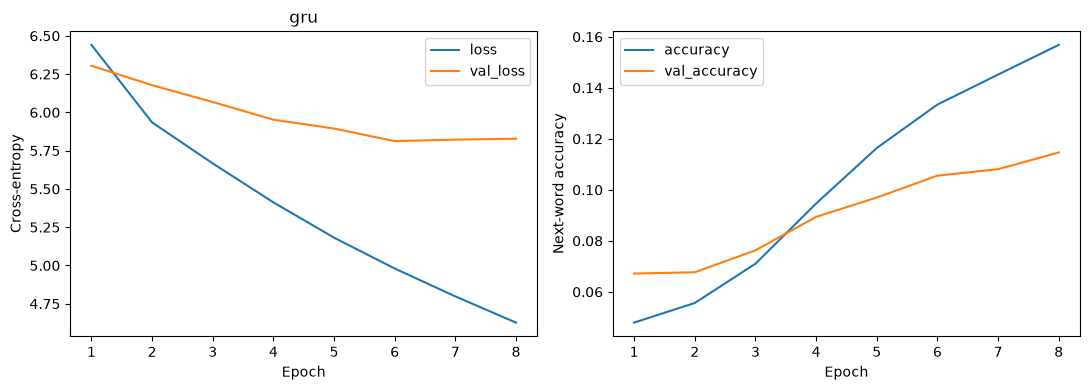

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(history.history['loss'])+1)
for key in ['loss', 'val_loss']:
    axes[0].plot(epochs, history.history[key], label=key)
for key in ['accuracy', 'val_accuracy']:
    axes[1].plot(epochs, history.history[key], label=key)
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy', title=MODEL_NAME)
axes[1].set(xlabel='Epoch', ylabel='Next-word accuracy')
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()


## 4. Autoregressive generation at three temperatures

In [6]:
samples = generate_grid(model, vocab, CONTEXT, count=60)
assert len(samples) == 27
assert all(len(sample['continuation'].split()) == 60 for sample in samples)
display(JSON({'samples': samples}))
for sample in samples:
    print(f"T={sample['temperature']} | RNG={sample['random_seed']} | Prompt: {sample['seed']}")
    print(sample['continuation'], '\n')


<IPython.core.display.JSON object>

T=0.2 | RNG=101 | Prompt: alice was beginning to get very tired
of the other of the other of the same thing she was very little deal of the hatter and she was a little little bit of the hatter and was a little deal of the hatter and was a little tone and she was to be a little little thing and was a little little thing to be with the 

T=0.2 | RNG=202 | Prompt: alice was beginning to get very tired
of the other of the hatter and was a little thing and was a little tone and she had not the other of the mouse was a little thing and was very little little key and was a little deal of the mouse was a little little thing and she had not a little deal of the hatter and was 

T=0.2 | RNG=303 | Prompt: alice was beginning to get very tired
of the other of the mouse was a little thing and she had not be a little thing and was and she was very little tone and she was not a little deal of the other of the other of the mouse was a little tone and the mouse was a little tone and the mouse was a lit

In [7]:
temperature_summary = []
for temperature in TEMPERATURES:
    group = [s for s in samples if s['temperature'] == temperature]
    row = {'temperature': temperature, 'sample_count': len(group)}
    for key in ['distinct_1', 'distinct_2', 'repeated_bigram_fraction']:
        row[key] = mean(s[key] for s in group)
    temperature_summary.append(row)
display(JSON({'temperature_summary': temperature_summary}))
lines = ['| Temperature | Distinct-1 | Distinct-2 | Repeated bigrams |',
         '|---|---|---|---|']
for row in temperature_summary:
    lines.append(f"| {row['temperature']:.1f} | {row['distinct_1']:.3f} | {row['distinct_2']:.3f} | {100*row['repeated_bigram_fraction']:.1f}% |")
display(Markdown('\n'.join(lines)))


<IPython.core.display.JSON object>

| Temperature | Distinct-1 | Distinct-2 | Repeated bigrams |
|---|---|---|---|
| 0.2 | 0.272 | 0.450 | 55.0% |
| 0.5 | 0.578 | 0.906 | 9.4% |
| 1.0 | 0.844 | 0.989 | 1.1% |